# 곁(GYEOT) 고령자 이상거래 탐지 v3 — 한계 수정과 실전형 검증

v2가 남긴 두 가지 한계를 고치고, v2의 숫자가 얼마나 믿을 만한지 검증한다.

| 구분 | v2 | v3 |
| --- | --- | --- |
| 기록 3건 미만 | z-score를 0으로 둠 → '기록 없음'과 '평소와 같음'이 구분 안 됨 | 수축 추정 z-score(`z_shrink`) + 과거 건수 피처(`hist_n`) |
| 스태킹 IF 점수 | 바깥 fold 점수를 학습 행에 그대로 사용 (근사) | 학습 데이터 안에서 다시 3-fold (nested CV) |
| 하이퍼파라미터 | 손으로 정한 값 | 학습 구간·학습 가구만으로 격자 탐색 |
| 검증 | 가구 단위 CV, 데이터 시드 1개 | 시드 5개 반복(편차), 시간순 검증(과거로 학습 → 미래 평가) |

**한 줄 결론**: 한계 수정은 탐지율의 평균을 올리지는 않았지만 시드 간 편차를 3분의 1로 줄였다. 시간순 검증에서는 PR-AUC가 0.43 → 0.27로 떨어졌다. v2의 CV 숫자에는 '미래 데이터로 학습한' 낙관이 섞여 있었다는 뜻이다. 탐지율 기준으로는 87% → 81%다.

데이터와 v2 모델 설명은 `gyeot_fraud_detection_v2.ipynb`에 있다. 이 노트북은 그 위에 얹는 실험만 다룬다.

In [1]:
import sys, json, os, time
sys.path.insert(0, "../src")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, matplotlib as mpl
from matplotlib import font_manager
from sklearn.metrics import average_precision_score
from gen_data import generate
from features import FEATURES
from features_v3 import build_features_v3, FEATURES_V3, K_SHRINK
import exp_seeds as X

for f in ["AppleGothic", "Malgun Gothic", "NanumGothic", "Noto Sans CJK KR", "Noto Sans CJK JP"]:
    if any(f == x.name for x in font_manager.fontManager.ttflist):
        mpl.rcParams["font.family"] = f; break
mpl.rcParams["axes.unicode_minus"] = False; mpl.rcParams["figure.dpi"] = 110
GREY, DARK, BLUE, RED = "#b0b4b8", "#5f6368", "#1a73e8", "#d93025"
SC_KO = {"impersonation": "사칭 송금", "cash_pickup": "대면편취(현금)", "loan_scam": "대출사기", "exploitation": "주변인 착취"}
def clean(ax): ax.spines[["top", "right"]].set_visible(False)

## 1. 기록 부족 문제: 수축 추정 z-score

v2의 `z_type`은 같은 유형 과거 거래가 3건 미만이면 0이다. 평가 거래 850,958건 중 1,008건이 여기에 해당하고, 그중 사기 거래가 57건이다. 가구 533의 1,865만 원 송금(과거 송금 0건)은 z=0으로 들어갔다.

수축 추정은 개인 평균을 집단 평균 쪽으로 당긴다.

$$\hat\mu = \frac{n\,\mu_{\text{개인}} + K\,\mu_{\text{집단}}}{n + K}, \qquad \hat\sigma^2 = \frac{(n-1)\,s^2_{\text{개인}} + K\,\sigma^2_{\text{집단}}}{(n-1) + K}$$

- n = 0이면 집단 기준, n이 커질수록 개인 기준이 된다. K = 5로 두면 과거 5건에서 개인과 집단이 반반이다.
- 집단 평균·분산은 평가 시작 전 3개월 거래로만 계산한다(누수 방지).
- `hist_n = log(1+n)`을 따로 넣어 모델이 '기록이 적다'는 사실 자체를 보게 한다.

In [2]:
df_raw, eps = generate(n_people=4000, seed=42)
df = build_features_v3(df_raw)
ev = df[df.ts >= pd.Timestamp("2025-04-01")].merge(eps[["episode", "scenario"]], on="episode", how="left").reset_index(drop=True)
lo = ev[ev.past_n < 3]
print(f"평가 거래 {len(ev):,}건 중 과거 기록 3건 미만 {len(lo):,}건 (사기 {int(lo.is_fraud.sum())}건)")
ex = ev[(ev.pid == 533) & (ev.amount > 1.8e7)][["pid", "ts", "type", "amount", "past_n", "z_type", "z_shrink"]]
ex

평가 거래 850,958건 중 과거 기록 3건 미만 1,008건 (사기 57건)


,pid,ts,type,amount,past_n,z_type,z_shrink
114105,533,2025-04-01 10:03:00,transfer_out,18654900.0,0,0.0,4.791554


가구 533의 거래는 `z_type` 0 → `z_shrink` 4.8이 됐다. 집단 기준으로 봐도 큰 송금이라는 정보가 살아난다.

단, 이 수정이 탐지율 자체를 크게 바꾸지는 않는다. 기록 부족 상태에서 시작하는 사기 에피소드는 대부분 대출사기(첫 대출 입금)인데, 이건 `loan_48h` 피처로 이미 100% 잡힌다. 수정의 효과는 2절의 '편차'에서 나타난다.

## 2. 시드 5개로 반복: v2 숫자는 얼마나 흔들리나

가상 데이터 생성 시드를 바꾸면 사기 사례도 바뀐다. 시드 5개로 전체 과정(데이터 생성 → 피처 → 가구 CV → LOSO → 2트랙 → 시간순 검증)을 반복해 평균과 표준편차를 본다.

비교 대상:

- `stack_v2`: v2 방식 그대로 (z_type, 비nested 스태킹, 기본 하이퍼파라미터)
- `stackN_v3_def`: v3 피처 + nested CV, 기본 하이퍼파라미터
- `stackN_v3_tun`: v3 피처 + nested CV + 튜닝한 하이퍼파라미터

시드 하나에 약 5분이 걸려 결과를 `results_seeds.json`에 저장해 둔다. 파일이 있으면 읽고, 없으면 다시 돌린다.

In [3]:
RES = "../results/results_seeds.json"
if os.path.exists(RES):
    R = json.load(open(RES))
else:
    R = []
    for sd in [42, 1, 2, 3, 4]:
        o, *_ = X.run(sd); R.append(o); print(sd, o["sec"], "s")
    os.makedirs("../results", exist_ok=True); json.dump(R, open(RES, "w"), ensure_ascii=False, indent=1, default=float)

rows = []
for r in R:
    for c, v in r["cv"].items():
        rows.append(dict(seed=r["seed"], 모델=c, PR_AUC=v["pr_auc"], 탐지율=v["recall"]))
cv = pd.DataFrame(rows)
summ = cv.groupby("모델")[["PR_AUC", "탐지율"]].agg(["mean", "std"]).round(3)
summ.loc[["iso_v2", "iso_v3", "stack_v2", "stackN_v3_def", "stackN_v3_tun"]]

PR_AUC           탐지율       
                mean    std   mean    std
모델                                       
iso_v2         0.064  0.004  0.542  0.021
iso_v3         0.064  0.006  0.546  0.036
stack_v2       0.356  0.050  0.871  0.032
stackN_v3_def  0.386  0.030  0.860  0.019
stackN_v3_tun  0.385  0.025  0.866  0.012

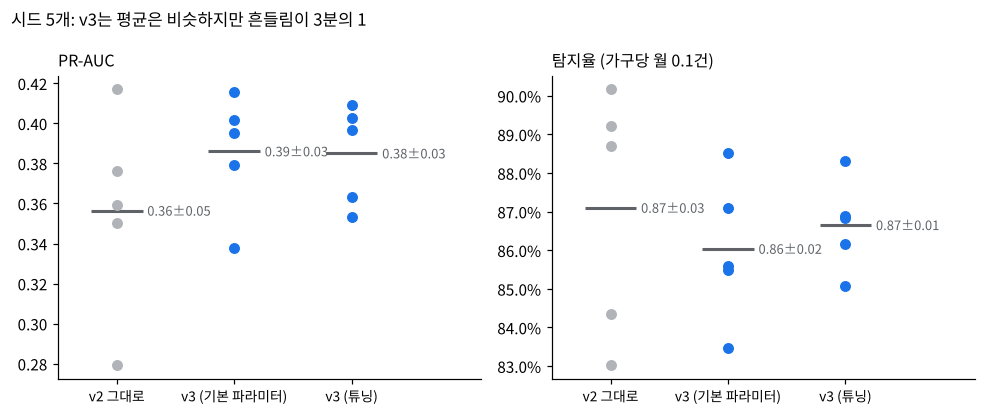

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
order = ["stack_v2", "stackN_v3_def", "stackN_v3_tun"]
label = {"stack_v2": "v2 그대로", "stackN_v3_def": "v3 (기본 파라미터)", "stackN_v3_tun": "v3 (튜닝)"}
for ax, col, ttl in [(axes[0], "PR_AUC", "PR-AUC"), (axes[1], "탐지율", "탐지율 (가구당 월 0.1건)")]:
    for i, m in enumerate(order):
        v = cv[cv.모델 == m][col]
        ax.scatter([i] * len(v), v, color=GREY if m == "stack_v2" else BLUE, s=38, zorder=3)
        ax.hlines(v.mean(), i - 0.22, i + 0.22, color=DARK, lw=2)
        ax.text(i + 0.26, v.mean(), f"{v.mean():.2f}±{v.std():.2f}", va="center", fontsize=8.5, color=DARK)
    ax.set_xticks(range(3)); ax.set_xticklabels([label[m] for m in order], fontsize=9); ax.set_xlim(-0.5, 3.1)
    ax.set_title(ttl, loc="left", fontsize=10.5); clean(ax)
axes[1].yaxis.set_major_formatter(mpl.ticker.PercentFormatter(1))
fig.suptitle("시드 5개: v3는 평균은 비슷하지만 흔들림이 3분의 1", x=0.01, ha="left", fontsize=11)
plt.tight_layout(); plt.show()

**읽는 법**

- v2 스태킹의 탐지율은 시드에 따라 83%~90%다. v2 노트북의 "90%"는 그중 좋은 쪽 시드였다. 평균은 87%다.
- v3는 탐지율 평균이 86~87%로 같지만, 표준편차가 0.032 → 0.012로 줄었다. PR-AUC는 0.356 → 0.386으로 조금 올랐다.
- 튜닝한 파라미터는 튜닝 구간 안에서는 PR-AUC 0.44로 기본값(0.42)보다 나았지만, 바깥 평가에서는 차이가 없다. 사기 244건짜리 데이터에서 PR-AUC 0.02 차이는 잡음 수준이라는 뜻이다. 튜닝 결과는 `results/tune_v3.csv`에 있다.

교훈은 단순하다. **시드 하나로 나온 소수점 셋째 자리는 의미가 없다.** 모델 비교는 반복 실험의 평균과 편차로 해야 한다.

## 3. 시간순 검증: 과거로 학습하고 미래를 평가

가구 단위 CV는 학습과 평가의 가구를 나누지만, **시간은 섞는다**. 2025년 12월 거래로 학습한 모델이 2025년 5월 거래를 평가하는 일이 생긴다. 실제 서비스는 반대다. 항상 과거로 학습해 미래를 판단한다.

그래서 같은 가구 분할을 유지한 채 두 가지를 비교한다.

- **시간순**: 학습 가구의 2025-04~08 거래로 학습 → 평가 가구의 2025-09~12 거래 평가
- **시간 섞음**: 학습 가구의 2025-04~12 전부로 학습 → 같은 평가 거래 평가

평가 거래가 같으니 차이는 '미래를 봤느냐'에서만 온다.

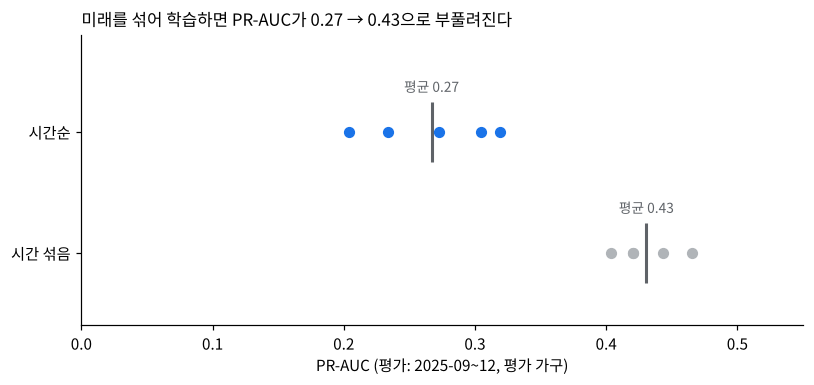

PR_AUC           탐지율       
        mean    std   mean    std
구분                               
시간 섞음  0.431  0.024  0.868  0.019
시간순    0.267  0.048  0.814  0.051

In [5]:
tm = pd.DataFrame([dict(seed=r["seed"], 구분=k, PR_AUC=r["time"][k]["pr_auc"], 탐지율=r["time"][k]["recall"])
                   for r in R for k in ["time", "leak"]])
t = tm.groupby("구분")[["PR_AUC", "탐지율"]].agg(["mean", "std"]).round(3).rename(index={"time": "시간순", "leak": "시간 섞음"})
fig, ax = plt.subplots(figsize=(7.5, 3.6))
for i, (k, lab, col) in enumerate([("leak", "시간 섞음 (CV 방식)", GREY), ("time", "시간순 (실전 방식)", BLUE)]):
    v = tm[tm.구분 == k]
    ax.scatter(v.PR_AUC, [i] * len(v), color=col, s=40, zorder=3, label=lab)
    ax.vlines(v.PR_AUC.mean(), i - 0.25, i + 0.25, color=DARK, lw=2)
    ax.text(v.PR_AUC.mean(), i + 0.33, f"평균 {v.PR_AUC.mean():.2f}", ha="center", fontsize=9, color=DARK)
ax.set_yticks([0, 1]); ax.set_yticklabels(["시간 섞음", "시간순"]); ax.set_ylim(-0.6, 1.8); ax.set_xlim(0, 0.55)
ax.set_xlabel("PR-AUC (평가: 2025-09~12, 평가 가구)")
ax.set_title("미래를 섞어 학습하면 PR-AUC가 0.27 → 0.43으로 부풀려진다", loc="left", fontsize=11)
clean(ax); plt.tight_layout(); plt.show()
t

**왜 떨어지나.** 두 가지가 겹친다.

1. 학습 사기 사례가 절반 가까이 준다(9개월 → 5개월).
2. 평가 구간(9~12월)의 거래는 과거 기록이 길어서 피처 분포가 학습 구간(4~8월)과 다르다. 섞어서 학습하면 모델이 '12월의 피처 분포'를 미리 본다.

탐지율로 보면 87% → 81%다. PR-AUC만큼 극적이지 않은 이유는, 알림 예산이 넉넉해서(월 0.1건) 점수 순위의 상단만 맞으면 되기 때문이다.

**v2 보고서의 숫자 중 어떤 걸 믿어야 하나.** 모델 간 상대 비교(스태킹 > 부스팅 > IF > 규칙)는 시간순에서도 유지된다. 절대 탐지율은 '87%'보다 '약 80%'가 실전에 가깝다. 포트폴리오와 제안서에는 이 숫자를 쓴다.

## 4. 2트랙 설계는 시간순에서도 유지되나

In [6]:
tt = pd.DataFrame([dict(seed=r["seed"], CV_아는사기_v2=r["twotrack_known_v2"], CV_처음보는_v2=r["twotrack_unseen_v2"],
                        CV_아는사기_v3=r["twotrack_known_v3"], CV_처음보는_v3=r["twotrack_unseen_v3"],
                        시간순_2트랙=r["time"]["twotrack"], 시간순_스태킹만=r["time"]["time"]["recall"], 시간순_IF만=r["time"]["iso"]["recall"]) for r in R])
tt.set_index("seed").agg(["mean", "std"]).T.round(3)

,mean,std
CV_아는사기_v2,0.818,0.045
CV_처음보는_v2,0.370,0.042
CV_아는사기_v3,0.837,0.012
CV_처음보는_v3,0.379,0.044
시간순_2트랙,0.788,0.056
시간순_스태킹만,0.814,0.051
시간순_IF만,0.573,0.086


- 가구 CV에서 IF 30% 2트랙은 v2와 v3 모두 '아는 사기' 82~84%, '처음 보는 사기' 37~38%다. v3가 여기서도 편차가 작다(0.045 → 0.012).
- 시간순에서는 2트랙이 스태킹 단독보다 탐지율이 2~3%p 낮다(79% vs 81%). 이 데이터의 평가 구간에는 '처음 보는 유형'이 없으니 당연한 비용이다. 처음 보는 유형이 나타나는 실제 환경에서는 그 비용으로 39%를 사는 셈이다. 결론은 바뀌지 않는다.

## 5. 정리

| 질문 | 답 |
| --- | --- |
| 기록 부족 구멍을 메우면 탐지율이 오르나 | 아니다. 평균은 같다. 대신 시드 간 편차가 3분의 1로 준다 |
| nested CV로 바꾸면 숫자가 바뀌나 | PR-AUC 기준 0.03 안팎이다. v2의 근사는 큰 거짓은 아니었다 |
| 튜닝 효과 | 튜닝 구간 안에서만 보인다. 바깥에서는 차이 없음. 사기 사례 수가 적어 PR-AUC 0.02는 잡음 |
| 시간순 검증 | PR-AUC 0.43 → 0.27, 탐지율 87% → 81%. 실전 숫자는 이쪽 |
| 2트랙 결론 | 유지. 시간순에서 2~3%p 비용 |

다음 단계로는 실제 신고 데이터 없이는 더 할 수 있는 게 적다. 남은 건 (1) 운영 중 라벨이 쌓일 때 모델을 언제 다시 학습할지, (2) 알림 뒤 가족의 응답(사기 맞음/아님)을 피처로 되먹이는 설계다.